<a href="https://colab.research.google.com/github/roopeshscs24-maker/BIS-lab/blob/main/SmartirrigationPSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pyswarms -q

Required irrigation: 3.72 mm/day

========== OPTIMAL IRRIGATION SCHEDULE ==========

Day 1
Morning : 2.89 mm
Afternoon : 1.39 mm
Evening : 0.89 mm
Total: 5.16 mm

Day 2
Morning : 1.56 mm
Afternoon : 1.72 mm
Evening : 2.16 mm
Total: 5.44 mm

Day 3
Morning : 0.4 mm
Afternoon : 1.13 mm
Evening : 2.25 mm
Total: 3.79 mm

Day 4
Morning : 1.5 mm
Afternoon : 0.69 mm
Evening : 2.21 mm
Total: 4.4 mm

Day 5
Morning : 0.59 mm
Afternoon : 3.4 mm
Evening : 0.2 mm
Total: 4.18 mm

Day 6
Morning : 3.39 mm
Afternoon : 0.54 mm
Evening : 2.36 mm
Total: 6.29 mm

Day 7
Morning : 1.2 mm
Afternoon : 0.66 mm
Evening : 3.04 mm
Total: 4.91 mm

========== FINAL RESULT ==========
Total water consumption: 34.16 mm
Daily water requirement: 3.72 mm
Weekly water requirement: 26.06 mm


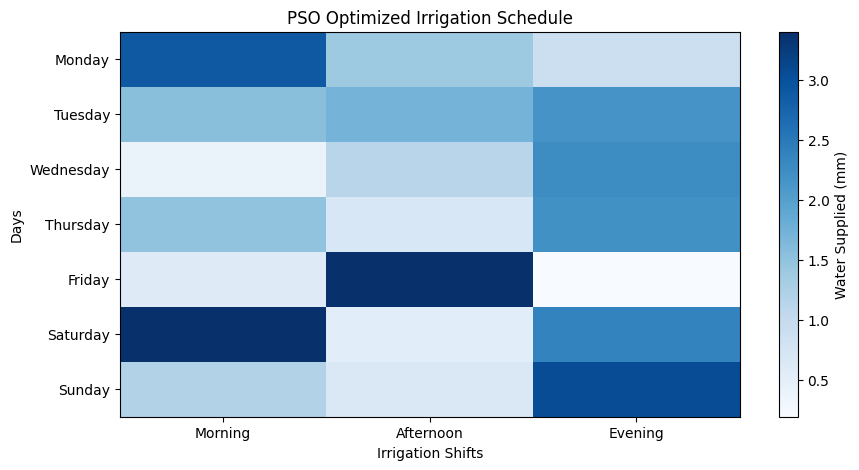

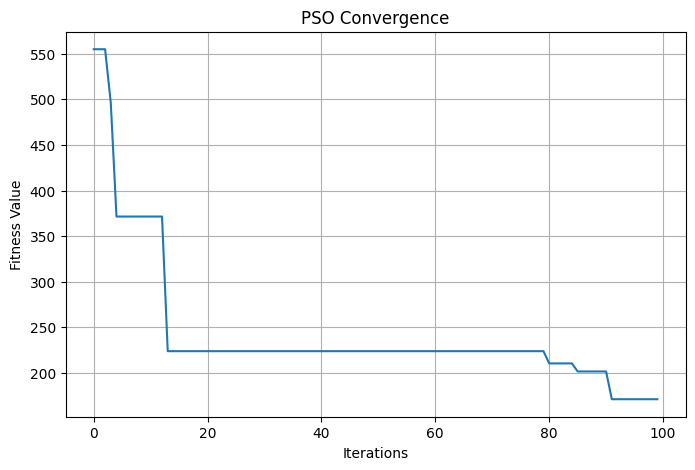

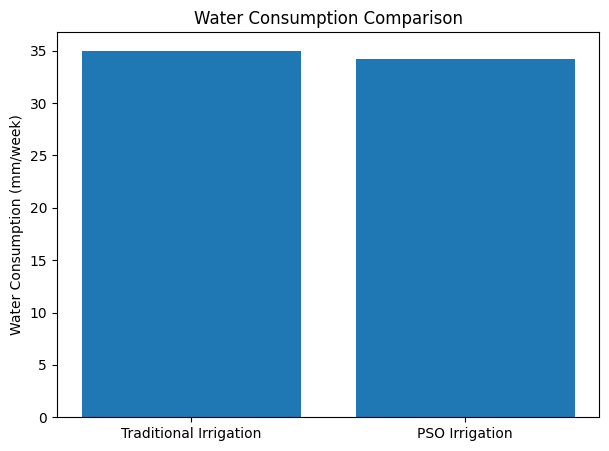

Water saved: 2.39 %


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pyswarms as ps

# ==========================================
# 1. INPUT PARAMETERS
# ==========================================

soil_moisture = 25       # Soil moisture (%)
temperature = 32         # Temperature (C)
humidity = 45            # Humidity (%)
rainfall = 2             # Rainfall (mm/day)
crop_water_req = 5       # Crop water requirement (mm/day)

days = 7

shifts = ["Morning", "Afternoon", "Evening"]

# ==========================================
# 2. CALCULATE WATER REQUIREMENT
# ==========================================

# Effective rainfall
effective_rainfall = rainfall * 0.8

# Soil water contribution
soil_water = max(0, (soil_moisture - 30) * 0.05)

# Net irrigation requirement
required_water = max(
    0,
    crop_water_req - effective_rainfall - soil_water
)

# Environmental adjustment
evaporation_factor = (
    1 + max(0, temperature - 25) * 0.01
    + max(0, 50 - humidity) * 0.005
)

required_water *= evaporation_factor

print("Required irrigation:", round(required_water, 2), "mm/day")

# ==========================================
# 3. PSO CONFIGURATION
# ==========================================

n_particles = 30
iterations = 100

# 7 days x 3 shifts = 21 variables
dimensions = days * len(shifts)

lower_bound = np.zeros(dimensions)

upper_bound = np.ones(dimensions) * 5

# ==========================================
# 4. FITNESS FUNCTION
# ==========================================

def fitness_function(particles):

    fitness = []

    for particle in particles:

        schedule = particle.reshape(days, 3)

        total_water = np.sum(schedule)

        penalty = 0

        # Check daily irrigation requirement
        for d in range(days):

            daily_water = np.sum(schedule[d])

            if daily_water < required_water:
                penalty += (required_water - daily_water) ** 2

        # Avoid unnecessary excess irrigation
        excess = 0

        for d in range(days):

            daily_water = np.sum(schedule[d])

            if daily_water > required_water:
                excess += (daily_water - required_water) ** 2

        cost = total_water + 1000 * penalty + 10 * excess

        fitness.append(cost)

    return np.array(fitness)

# ==========================================
# 5. RUN PARTICLE SWARM OPTIMIZATION
# ==========================================

options = {
    'c1': 1.5,
    'c2': 1.5,
    'w': 0.7
}

optimizer = ps.single.GlobalBestPSO(
    n_particles=n_particles,
    dimensions=dimensions,
    options=options,
    bounds=(lower_bound, upper_bound)
)

best_cost, best_position = optimizer.optimize(
    fitness_function,
    iters=iterations,
    verbose=False
)

# ==========================================
# 6. OPTIMAL IRRIGATION SCHEDULE
# ==========================================

optimal_schedule = best_position.reshape(days, 3)

print("\n========== OPTIMAL IRRIGATION SCHEDULE ==========")

for d in range(days):

    print("\nDay", d + 1)

    for s in range(3):

        print(
            shifts[s],
            ":",
            round(optimal_schedule[d][s], 2),
            "mm"
        )

    print(
        "Total:",
        round(np.sum(optimal_schedule[d]), 2),
        "mm"
    )

# ==========================================
# 7. TOTAL WATER CONSUMPTION
# ==========================================

total_water = np.sum(optimal_schedule)

print("\n========== FINAL RESULT ==========")

print("Total water consumption:",
      round(total_water, 2), "mm")

print("Daily water requirement:",
      round(required_water, 2), "mm")

print("Weekly water requirement:",
      round(required_water * days, 2), "mm")

# ==========================================
# 8. IRRIGATION SCHEDULE GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.imshow(optimal_schedule, cmap="Blues", aspect="auto")

plt.colorbar(label="Water Supplied (mm)")

plt.xticks(range(3), shifts)

plt.yticks(range(7), [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

plt.xlabel("Irrigation Shifts")

plt.ylabel("Days")

plt.title("PSO Optimized Irrigation Schedule")

plt.show()

# ==========================================
# 9. PSO CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(optimizer.cost_history)

plt.xlabel("Iterations")

plt.ylabel("Fitness Value")

plt.title("PSO Convergence")

plt.grid(True)

plt.show()

# ==========================================
# 10. WATER CONSUMPTION COMPARISON
# ==========================================

traditional_water = crop_water_req * days

pso_water = total_water

plt.figure(figsize=(7, 5))

plt.bar(
    ["Traditional Irrigation", "PSO Irrigation"],
    [traditional_water, pso_water]
)

plt.ylabel("Water Consumption (mm/week)")

plt.title("Water Consumption Comparison")

plt.show()

water_saved = (
    (traditional_water - pso_water)
    / traditional_water
) * 100

print("Water saved:", round(water_saved, 2), "%")